# SupplySense — Corrected Demand Forecasting Notebook

**Purpose:** Build, evaluate, save and use a 7-day category-level demand forecasting model.

## Important corrections in this version

1. Accepts either the enriched transaction-level CSV (`quantity`) or the already-aggregated daily/category CSV (`total_quantity_sold`). Both are normalized to the same target column before feature engineering.
2. Fills missing dates with zero **only inside each category's observed start/end period**. This assumes the source transaction export is complete.
3. Uses a common date window for validation and test, so every category is evaluated on the same calendar dates.
4. Uses multiple rolling 7-day validation windows for hyperparameter selection.
5. Includes festival features in both training and recursive forecasting.
6. Computes category-level MASE using training data only.
7. Compares HistGradientBoosting against a recursive Lag-7 baseline on identical observations.
8. Creates a future festival-calendar template rather than silently using placeholder festival values.

**Important data limitation:** In the uploaded source, six categories end on 2023-12-31, while Clothing & Apparel continues to 2024-10-11. Therefore, the common evaluation period is limited by the overlap. Forecasts after each category's last available date will have different start dates. They are historical forecasts, not current 2026 demand forecasts. Update the source with recent transactions for all categories before deployment.

Run every section from top to bottom.

## Section 1 — Import libraries

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detect Google Colab and prepare Drive/file-upload helpers before they are used.
try:
    from google.colab import drive, files
    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False
    files = None

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Libraries imported successfully.")

Mounted at /content/drive
Libraries imported successfully.


## Section 2 — Mount Google Drive and select the source file

The notebook detects Google Colab, mounts Drive, and prepares the upload helper.
It accepts either `sales_dataset_enriched_for_ml(1).csv` or `supply_sense_daily_category_training.csv`. The loader recognizes `quantity` and `total_quantity_sold` automatically.


In [2]:
# Accept either the enriched transaction-level CSV (quantity) OR the already
# aggregated daily/category training CSV (total_quantity_sold).
BASE_REQUIRED_COLUMNS = {
    "saleDate",
    "productCategory",
    "Festival_Nearby_Within_10_Days",
    "Days_To_Festival",
}
TARGET_CANDIDATES = {"quantity", "total_quantity_sold"}

def inspect_source_csv(csv_path):
    try:
        columns = set(pd.read_csv(csv_path, nrows=0).columns)
        missing_base = BASE_REQUIRED_COLUMNS - columns
        has_target = bool(TARGET_CANDIDATES & columns)
        return not missing_base and has_target, columns
    except Exception:
        return False, set()

if IN_COLAB:
    drive_folder = Path("/content/drive/MyDrive/Colab Notebooks")
    candidate_paths = [
        drive_folder / "sales_dataset_enriched_for_ml(1).csv",
        drive_folder / "sales_dataset_enriched_for_ml.csv",
        drive_folder / "final_randomized_sales_dataset.csv",
        drive_folder / "final_sales_dataset.csv",
        drive_folder / "supply_sense_daily_category_training.csv",
        Path("sales_dataset_enriched_for_ml(1).csv"),
        Path("sales_dataset_enriched_for_ml.csv"),
        Path("supply_sense_daily_category_training.csv"),
    ]
else:
    candidate_paths = [
        Path("sales_dataset_enriched_for_ml(1).csv"),
        Path("sales_dataset_enriched_for_ml.csv"),
        Path("final_randomized_sales_dataset.csv"),
        Path("final_sales_dataset.csv"),
        Path("supply_sense_daily_category_training.csv"),
    ]

DATA_PATH = None
for candidate in candidate_paths:
    if candidate.exists():
        valid, columns = inspect_source_csv(candidate)
        if valid:
            DATA_PATH = candidate
            break
        print(f"Skipping {candidate.name}: missing base columns "
              f"{sorted(BASE_REQUIRED_COLUMNS - columns)} or target column "
              f"(one of {sorted(TARGET_CANDIDATES)}).")

if DATA_PATH is None and IN_COLAB:
    print("Upload either the enriched transaction-level CSV (quantity) OR "
          "supply_sense_daily_category_training.csv (total_quantity_sold).")
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith(".csv"):
            valid, columns = inspect_source_csv(name)
            if valid:
                DATA_PATH = Path(name)
                break
            print(f"Skipping {name}: incompatible columns. Found: {sorted(columns)}")

if DATA_PATH is None:
    raise FileNotFoundError(
        "No compatible CSV found. Required: saleDate, productCategory, "
        "Festival_Nearby_Within_10_Days, Days_To_Festival, and either "
        "quantity or total_quantity_sold."
    )

print("Using dataset:", DATA_PATH.resolve())


Using dataset: /content/drive/MyDrive/Colab Notebooks/supply_sense_daily_category_training.csv


## Section 3 — Configuration

In [3]:
DATE_COL = "saleDate"
GROUP_COL = "productCategory"
RAW_TARGET = "quantity"
TARGET = "total_quantity_sold"

FESTIVAL_FLAG = "Festival_Nearby_Within_10_Days"
DAYS_TO_FESTIVAL = "Days_To_Festival"
FESTIVAL_FEATURES = [FESTIVAL_FLAG, DAYS_TO_FESTIVAL]

HORIZON = 7
RANDOM_STATE = 42

# Historical features. All are computed using past observations only.
LAGS = (1, 7, 14, 28, 56)
ROLLING_WINDOWS = (7, 14, 28)

OUTPUT_DIR = Path("supplysense_corrected_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration ready.")

Configuration ready.


## Section 4 — Load and normalize the dataset

In [4]:
raw = pd.read_csv(DATA_PATH)

# Normalize both supported source formats to the same target column.
if RAW_TARGET not in raw.columns and TARGET in raw.columns:
    raw = raw.rename(columns={TARGET: RAW_TARGET})

required_columns = [
    DATE_COL,
    GROUP_COL,
    RAW_TARGET,
    FESTIVAL_FLAG,
    DAYS_TO_FESTIVAL
]

missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from source CSV: {missing_columns}")

raw[DATE_COL] = pd.to_datetime(raw[DATE_COL], errors="coerce")
raw[RAW_TARGET] = pd.to_numeric(raw[RAW_TARGET], errors="coerce")
raw[FESTIVAL_FLAG] = pd.to_numeric(raw[FESTIVAL_FLAG], errors="coerce")
raw[DAYS_TO_FESTIVAL] = pd.to_numeric(raw[DAYS_TO_FESTIVAL], errors="coerce")

print("Raw dataset shape:", raw.shape)
print("Source target column normalized to:", RAW_TARGET)
display(raw.head())


Raw dataset shape: (14777, 14)
Source target column normalized to: quantity


,saleDate,productCategory,Month,Day_of_Week,Festival_Nearby_Within_10_Days,Days_To_Festival,Category_Clothing & Apparel,Category_Dairy Products,Category_Electronics & Appliances,Category_Food,Category_Fruits & Vegetables,Category_Furniture,Category_Household Items,quantity
0,2019-01-01,Clothing & Apparel,1,1,0,12,1,0,0,0,0,0,0,0.0
1,2019-01-01,Dairy Products,1,1,0,12,0,1,0,0,0,0,0,58.0
2,2019-01-01,Electronics & Appliances,1,1,0,12,0,0,1,0,0,0,0,81.0
3,2019-01-01,Food,1,1,0,12,0,0,0,1,0,0,0,71.0
4,2019-01-01,Fruits & Vegetables,1,1,0,12,0,0,0,0,1,0,0,57.0


## Section 5 — Data quality checks

In [5]:
print("Missing values in required columns:")
display(raw[required_columns].isna().sum().to_frame("missing_count"))

print("Exact duplicate rows:", int(raw.duplicated().sum()))

if "serialNo" in raw.columns:
    print("Duplicate serialNo values:", int(raw["serialNo"].duplicated().sum()))

# Remove only rows that cannot be used for the requested target/features.
raw = raw.dropna(subset=required_columns).copy()
raw = raw[raw[RAW_TARGET] >= 0].copy()

raw[GROUP_COL] = raw[GROUP_COL].astype(str).str.strip()
raw[FESTIVAL_FLAG] = raw[FESTIVAL_FLAG].astype(int)

if not raw[FESTIVAL_FLAG].isin([0, 1]).all():
    raise ValueError("Festival flag must contain only 0 and 1.")

if (raw[DAYS_TO_FESTIVAL] < 0).any():
    raise ValueError("Days_To_Festival contains negative values.")

# Festival features should be date-level values, consistent across categories.
daily_feature_variation = (
    raw.groupby(DATE_COL)[FESTIVAL_FEATURES]
       .nunique(dropna=False)
)

inconsistent_dates = daily_feature_variation[
    (daily_feature_variation > 1).any(axis=1)
]

if len(inconsistent_dates):
    raise ValueError(
        "Festival values are inconsistent within these dates. "
        f"Example dates: {list(inconsistent_dates.index[:10])}"
    )

print("Clean transaction rows:", len(raw))
print("Categories:", sorted(raw[GROUP_COL].unique()))
print("Date range:", raw[DATE_COL].min(), "to", raw[DATE_COL].max())

Missing values in required columns:


,missing_count
saleDate,0
productCategory,0
quantity,0
Festival_Nearby_Within_10_Days,0
Days_To_Festival,0


Exact duplicate rows: 0
Clean transaction rows: 14777
Categories: ['Clothing & Apparel', 'Dairy Products', 'Electronics & Appliances', 'Food', 'Fruits & Vegetables', 'Furniture', 'Household Items']
Date range: 2019-01-01 00:00:00 to 2024-10-11 00:00:00


## Section 6 — Build a date-level festival calendar

Festival information is common to all categories on a given date. We validate that assumption above, then create one calendar row per date.

In [6]:
calendar_daily = (
    raw.groupby(DATE_COL)[FESTIVAL_FEATURES]
       .first()
       .reset_index()
       .rename(columns={DATE_COL: "date"})
       .sort_values("date")
)

display(calendar_daily.head())
print("Festival calendar rows:", len(calendar_daily))

,date,Festival_Nearby_Within_10_Days,Days_To_Festival
0,2019-01-01,0,12
1,2019-01-02,0,11
2,2019-01-03,1,10
3,2019-01-04,1,9
4,2019-01-05,1,8


Festival calendar rows: 2111


## Section 7 — Aggregate sales by category and date

The panel is rebuilt from the transaction-level file.

A missing date is filled with zero only between a category's first and last observed transaction dates. This assumes the uploaded CSV is a complete transaction export for that category and period. We do **not** extend a category before its first transaction or after its last transaction.

In [7]:
daily_sales = (
    raw.groupby([DATE_COL, GROUP_COL], as_index=False)[RAW_TARGET]
       .sum()
       .rename(columns={DATE_COL: "date", RAW_TARGET: TARGET})
)

categories = sorted(daily_sales[GROUP_COL].unique())
panel_parts = []
filled_day_counts = {}

for category in categories:
    part = (
        daily_sales.loc[daily_sales[GROUP_COL] == category]
        .set_index("date")[TARGET]
        .sort_index()
    )

    full_dates = pd.date_range(part.index.min(), part.index.max(), freq="D")
    missing_dates = full_dates.difference(part.index)
    filled_day_counts[category] = len(missing_dates)

    # Assumption: absent transaction date inside observed coverage means zero sales.
    part = part.reindex(full_dates, fill_value=0)
    part.index.name = "date"

    category_panel = part.rename(TARGET).reset_index()
    category_panel[GROUP_COL] = category
    panel_parts.append(category_panel)

panel = pd.concat(panel_parts, ignore_index=True)

panel = panel.merge(
    calendar_daily,
    on="date",
    how="left",
    validate="many_to_one"
)

if panel[FESTIVAL_FEATURES].isna().any().any():
    missing_calendar_dates = (
        panel.loc[panel[FESTIVAL_FEATURES].isna().any(axis=1), "date"]
        .drop_duplicates()
        .tolist()
    )
    raise ValueError(
        "Festival calendar is missing dates inside observed category coverage. "
        f"Add verified calendar values for: {missing_calendar_dates[:10]}"
    )

panel = panel.sort_values([GROUP_COL, "date"]).reset_index(drop=True)

print("Daily panel shape:", panel.shape)
print("Inserted zero-sales dates inside observed coverage:")
display(pd.Series(filled_day_counts, name="filled_zero_dates").to_frame())

display(panel.head(10))

Daily panel shape: (14777, 5)
Inserted zero-sales dates inside observed coverage:


,filled_zero_dates
Clothing & Apparel,0
Dairy Products,0
Electronics & Appliances,0
Food,0
Fruits & Vegetables,0
Furniture,0
Household Items,0


,date,total_quantity_sold,productCategory,Festival_Nearby_Within_10_Days,Days_To_Festival
0,2019-01-01,0.0,Clothing & Apparel,0,12
1,2019-01-02,0.0,Clothing & Apparel,0,11
2,2019-01-03,0.0,Clothing & Apparel,1,10
3,2019-01-04,0.0,Clothing & Apparel,1,9
4,2019-01-05,0.0,Clothing & Apparel,1,8
5,2019-01-06,0.0,Clothing & Apparel,1,7
6,2019-01-07,0.0,Clothing & Apparel,1,6
7,2019-01-08,0.0,Clothing & Apparel,1,5
8,2019-01-09,0.0,Clothing & Apparel,1,4
9,2019-01-10,0.0,Clothing & Apparel,1,3


## Section 8 — Inspect category date coverage

In [8]:
coverage = (
    panel.groupby(GROUP_COL)["date"]
         .agg(first_date="min", last_date="max", daily_rows="count")
)

coverage["calendar_days"] = (
    coverage["last_date"] - coverage["first_date"]
).dt.days + 1

coverage["coverage_complete"] = (
    coverage["daily_rows"] == coverage["calendar_days"]
)

display(coverage)

common_start = coverage["first_date"].max()
common_end = coverage["last_date"].min()

if common_start > common_end:
    raise ValueError("There is no common historical period across all categories.")

common_dates = pd.date_range(common_start, common_end, freq="D")

print("Common evaluation period:", common_start.date(), "to", common_end.date())
print("Number of common days:", len(common_dates))

for category in categories:
    category_dates = pd.DatetimeIndex(
        panel.loc[
            (panel[GROUP_COL] == category) &
            panel["date"].between(common_start, common_end),
            "date"
        ].unique()
    )
    if len(category_dates) != len(common_dates):
        raise ValueError(
            f"{category} does not have a complete daily panel in the common period."
        )

,first_date,last_date,daily_rows,calendar_days,coverage_complete
productCategory,,,,,
Clothing & Apparel,2019-01-01,2024-10-11,2111,2111,True
Dairy Products,2019-01-01,2024-10-11,2111,2111,True
Electronics & Appliances,2019-01-01,2024-10-11,2111,2111,True
Food,2019-01-01,2024-10-11,2111,2111,True
Fruits & Vegetables,2019-01-01,2024-10-11,2111,2111,True
Furniture,2019-01-01,2024-10-11,2111,2111,True
Household Items,2019-01-01,2024-10-11,2111,2111,True


Common evaluation period: 2019-01-01 to 2024-10-11
Number of common days: 2111


## Section 9 — Visualize daily demand

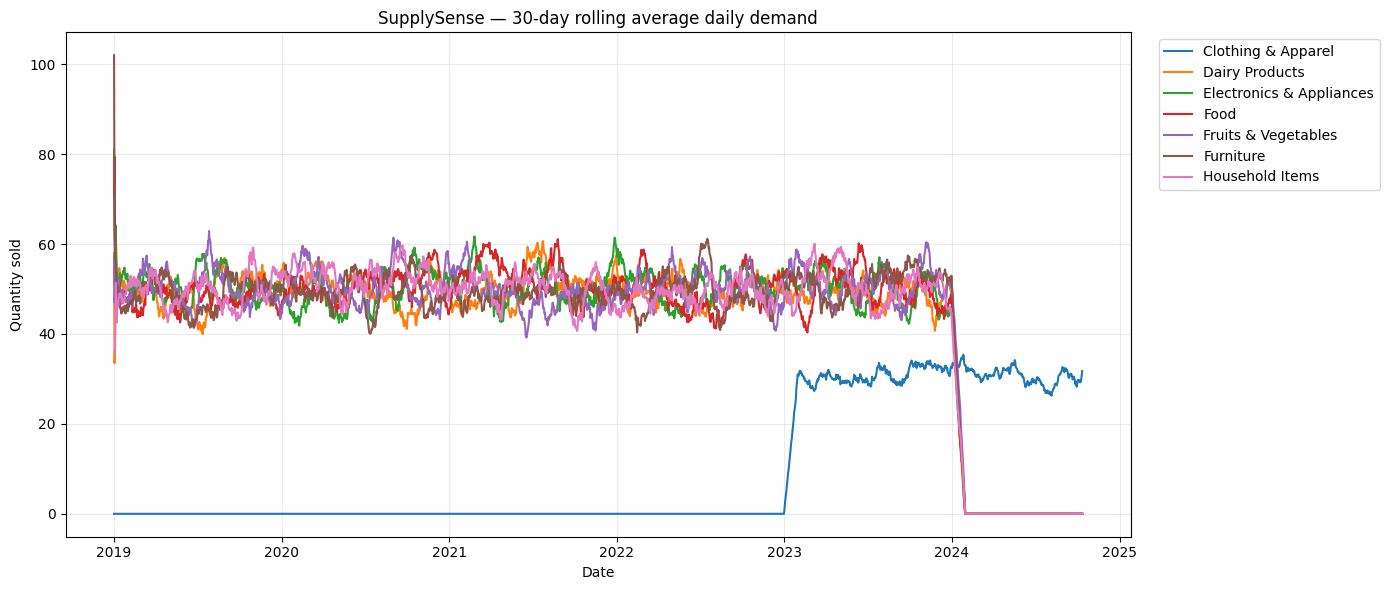

In [9]:
plt.figure(figsize=(14, 6))

for category in categories:
    subset = panel[panel[GROUP_COL] == category]
    rolling = (
        subset.set_index("date")[TARGET]
        .rolling(30, min_periods=1)
        .mean()
    )
    plt.plot(rolling.index, rolling.values, label=category)

plt.title("SupplySense — 30-day rolling average daily demand")
plt.xlabel("Date")
plt.ylabel("Quantity sold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Section 10 — Calendar and lag feature engineering

All lag and rolling features use previous observations only. Festival features are included in training and must also be supplied for future forecast dates.

In [10]:
def make_calendar_features(date):
    date = pd.Timestamp(date)
    dow = date.dayofweek
    doy = date.dayofyear
    week = int(date.isocalendar().week)
    month = date.month

    return {
        "day_of_week": dow,
        "day_of_month": date.day,
        "month": month,
        "week_of_year": week,
        "quarter": date.quarter,
        "is_weekend": int(dow >= 5),
        "day_of_year_sin": np.sin(2 * np.pi * doy / 365.25),
        "day_of_year_cos": np.cos(2 * np.pi * doy / 365.25),
        "month_sin": np.sin(2 * np.pi * month / 12),
        "month_cos": np.cos(2 * np.pi * month / 12),
        "dow_sin": np.sin(2 * np.pi * dow / 7),
        "dow_cos": np.cos(2 * np.pi * dow / 7)
    }


def prepare_features(data):
    data = data.sort_values([GROUP_COL, "date"]).copy()
    grouped = data.groupby(GROUP_COL)[TARGET]

    for lag in LAGS:
        data[f"lag_{lag}"] = grouped.shift(lag)

    for window in ROLLING_WINDOWS:
        shifted = data.groupby(GROUP_COL)[TARGET].transform(lambda s, w=window: s.shift(1).rolling(w).mean())
        data[f"roll_mean_{window}"] = shifted

        data[f"roll_median_{window}"] = (
            data.groupby(GROUP_COL)[TARGET]
                .transform(lambda s, w=window: s.shift(1).rolling(w).median())
        )

        data[f"roll_std_{window}"] = (
            data.groupby(GROUP_COL)[TARGET]
                .transform(lambda s, w=window: s.shift(1).rolling(w).std())
                .fillna(0)
        )

    data["roll_max_7"] = (
        data.groupby(GROUP_COL)[TARGET]
            .transform(lambda s: s.shift(1).rolling(7).max())
    )

    calendar_frame = pd.DataFrame(
        [make_calendar_features(d) for d in data["date"]],
        index=data.index
    )
    data = pd.concat([data, calendar_frame], axis=1)

    for i, category in enumerate(categories):
        data[f"category_{i}"] = (data[GROUP_COL] == category).astype(int)

    lag_columns = [f"lag_{lag}" for lag in LAGS]
    rolling_mean_columns = [f"roll_mean_{w}" for w in ROLLING_WINDOWS]

    category_columns = [f"category_{i}" for i in range(len(categories))]
    calendar_columns = list(calendar_frame.columns)

    feature_columns = (
        lag_columns
        + rolling_mean_columns
        + [f"roll_median_{w}" for w in ROLLING_WINDOWS]
        + [f"roll_std_{w}" for w in ROLLING_WINDOWS]
        + ["roll_max_7"]
        + calendar_columns
        + FESTIVAL_FEATURES
        + category_columns
    )

    required_feature_rows = lag_columns + rolling_mean_columns + FESTIVAL_FEATURES
    data = data.dropna(subset=required_feature_rows).reset_index(drop=True)

    return data, feature_columns


feature_data, feature_columns = prepare_features(panel)

print("Feature rows:", len(feature_data))
print("Number of model features:", len(feature_columns))
print("Features:", feature_columns)
display(feature_data.head())

Feature rows: 14385
Number of model features: 36
Features: ['lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_mean_14', 'roll_mean_28', 'roll_median_7', 'roll_median_14', 'roll_median_28', 'roll_std_7', 'roll_std_14', 'roll_std_28', 'roll_max_7', 'day_of_week', 'day_of_month', 'month', 'week_of_year', 'quarter', 'is_weekend', 'day_of_year_sin', 'day_of_year_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'Festival_Nearby_Within_10_Days', 'Days_To_Festival', 'category_0', 'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6']


,date,total_quantity_sold,productCategory,Festival_Nearby_Within_10_Days,Days_To_Festival,lag_1,lag_7,lag_14,lag_28,lag_56,roll_mean_7,roll_median_7,roll_std_7,roll_mean_14,roll_median_14,roll_std_14,roll_mean_28,roll_median_28,roll_std_28,roll_max_7,day_of_week,day_of_month,month,week_of_year,quarter,is_weekend,day_of_year_sin,day_of_year_cos,month_sin,month_cos,dow_sin,dow_cos,category_0,category_1,category_2,category_3,category_4,category_5,category_6
0,2019-02-26,0.0,Clothing & Apparel,1,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,26,2,9,1,0,0.830797,0.556576,0.866025,5.000000e-01,0.781831,0.623490,1,0,0,0,0,0,0
1,2019-02-27,0.0,Clothing & Apparel,1,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,27,2,9,1,0,0.840248,0.542202,0.866025,5.000000e-01,0.974928,-0.222521,1,0,0,0,0,0,0
2,2019-02-28,0.0,Clothing & Apparel,1,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3,28,2,9,1,0,0.849450,0.527668,0.866025,5.000000e-01,0.433884,-0.900969,1,0,0,0,0,0,0
3,2019-03-01,0.0,Clothing & Apparel,1,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4,1,3,9,1,0,0.858402,0.512978,1.000000,6.123234e-17,-0.433884,-0.900969,1,0,0,0,0,0,0
4,2019-03-02,0.0,Clothing & Apparel,1,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5,2,3,9,1,1,0.867099,0.498137,1.000000,6.123234e-17,-0.974928,-0.222521,1,0,0,0,0,0,0


## Section 11 — Create chronological validation and test windows

All categories use the **same calendar dates** for validation and testing.

- Last 7 common days: final test window.
- The 35 days before the test window: five consecutive 7-day validation windows.
- Hyperparameters are selected using validation windows only.

In [11]:
if len(common_dates) < 120:
    raise ValueError(
        "The common history is too short for this validation design. "
        "Use more overlapping historical data or reduce the number of validation windows."
    )

test_dates_common = common_dates[-7:]
test_start = test_dates_common[0]

validation_windows = []
validation_region = common_dates[-42:-7]

for start in range(0, len(validation_region), 7):
    window = validation_region[start:start + 7]
    if len(window) == 7:
        validation_windows.append(pd.DatetimeIndex(window))

if len(validation_windows) != 5:
    raise ValueError("Expected five complete 7-day validation windows.")

print("Validation windows:")
for i, window in enumerate(validation_windows, 1):
    print(i, window[0].date(), "to", window[-1].date())

print("Test:", test_dates_common[0].date(), "to", test_dates_common[-1].date())

dates_by_category_test = {
    category: test_dates_common for category in categories
}

Validation windows:
1 2024-08-31 to 2024-09-06
2 2024-09-07 to 2024-09-13
3 2024-09-14 to 2024-09-20
4 2024-09-21 to 2024-09-27
5 2024-09-28 to 2024-10-04
Test: 2024-10-05 to 2024-10-11


## Section 12 — Build the date-level calendar lookup

In [12]:
calendar_by_date = (
    panel[["date"] + FESTIVAL_FEATURES]
    .drop_duplicates("date")
    .set_index("date")
    .to_dict(orient="index")
)

print("Calendar lookup prepared for", len(calendar_by_date), "dates.")

Calendar lookup prepared for 2111 dates.


## Section 13 — Define evaluation metrics

In [13]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted) if len(actual) > 1 else np.nan

    denominator = np.abs(actual).sum()
    wape = (
        np.abs(actual - predicted).sum() / denominator * 100
        if denominator > 0 else np.nan
    )

    bias_pct = (
        (predicted - actual).sum() / denominator * 100
        if denominator > 0 else np.nan
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "R2": float(r2),
        "WAPE (%)": float(wape),
        "Bias (%)": float(bias_pct)
    }

print("Metric function ready.")

Metric function ready.


## Section 14 — Define recursive feature construction

The same feature definitions are used during training and forecasting. Missing lag dates raise an error instead of silently becoming zero.

In [14]:
def build_prediction_row(date, category, history, calendar_lookup):
    date = pd.Timestamp(date)
    s = history[category]

    if date not in calendar_lookup:
        raise ValueError(f"Festival/calendar inputs missing for forecast date {date.date()}.")

    row = make_calendar_features(date)
    row.update(calendar_lookup[date])

    for lag in LAGS:
        lag_date = date - pd.Timedelta(days=lag)
        value = s.get(lag_date, np.nan)
        if pd.isna(value):
            raise ValueError(
                f"Missing lag-{lag} history for {category} on {date.date()}."
            )
        row[f"lag_{lag}"] = float(value)

    for window in ROLLING_WINDOWS:
        window_dates = pd.date_range(
            end=date - pd.Timedelta(days=1),
            periods=window,
            freq="D"
        )
        values = s.reindex(window_dates)

        if values.isna().any():
            raise ValueError(
                f"Missing rolling history for {category} on {date.date()}."
            )

        values = values.to_numpy(dtype=float)
        row[f"roll_mean_{window}"] = float(np.mean(values))
        row[f"roll_median_{window}"] = float(np.median(values))
        row[f"roll_std_{window}"] = float(np.std(values, ddof=1))

    last_7_dates = pd.date_range(
        end=date - pd.Timedelta(days=1),
        periods=7,
        freq="D"
    )
    last_7 = s.reindex(last_7_dates)

    if last_7.isna().any():
        raise ValueError(f"Missing 7-day maximum history for {category} on {date.date()}.")

    row["roll_max_7"] = float(last_7.max())

    for i, cat in enumerate(categories):
        row[f"category_{i}"] = int(category == cat)

    return row


def recursive_forecast(model, history_data, dates_by_category, calendar_lookup, use_model=True):
    history = {}

    for category in categories:
        category_history = (
            history_data.loc[history_data[GROUP_COL] == category]
            .set_index("date")[TARGET]
            .sort_index()
        )

        if category_history.empty:
            raise ValueError(f"No history available for category: {category}")

        history[category] = category_history.copy()

    predictions = []

    for category in categories:
        for date in pd.DatetimeIndex(dates_by_category[category]).sort_values():
            row = build_prediction_row(
                date=date,
                category=category,
                history=history,
                calendar_lookup=calendar_lookup
            )

            X_one = pd.DataFrame([row]).reindex(columns=feature_columns)

            if X_one.isna().any().any():
                raise ValueError("Prediction row contains missing model features.")

            if use_model:
                prediction = float(model.predict(X_one)[0])
            else:
                lag_date = pd.Timestamp(date) - pd.Timedelta(days=7)
                prediction = history[category].get(lag_date, np.nan)
                if pd.isna(prediction):
                    raise ValueError(
                        f"Lag-7 baseline history missing for {category} on {date.date()}."
                    )
                prediction = float(prediction)

            prediction = max(0.0, prediction)

            predictions.append({
                "date": pd.Timestamp(date),
                GROUP_COL: category,
                "prediction": prediction
            })

            # Recursive step: use the prediction as history for later horizon days.
            history[category].loc[pd.Timestamp(date)] = prediction

    return (
        pd.DataFrame(predictions)
        .sort_values(["date", GROUP_COL])
        .reset_index(drop=True)
    )

print("Recursive forecasting functions ready.")

Recursive forecasting functions ready.


## Section 15 — Define candidate HistGradientBoosting configurations

In [15]:
candidates = [
    {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 15,
        "max_depth": 5,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0
    },
    {
        "max_iter": 300,
        "learning_rate": 0.03,
        "max_leaf_nodes": 15,
        "max_depth": 5,
        "min_samples_leaf": 30,
        "l2_regularization": 2.0
    },
    {
        "max_iter": 300,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "max_depth": 6,
        "min_samples_leaf": 30,
        "l2_regularization": 3.0
    },
    {
        "max_iter": 500,
        "learning_rate": 0.02,
        "max_leaf_nodes": 31,
        "max_depth": 6,
        "min_samples_leaf": 50,
        "l2_regularization": 5.0
    }
]

print("Configurations to evaluate:", len(candidates))

Configurations to evaluate: 4


## Section 16 — Tune using five rolling 7-day validation windows

Each candidate is retrained at each validation origin. Forecasts are recursive for all seven days. The selected configuration minimizes validation WAPE, with MAE as a tie-breaker.

In [16]:
validation_actual_parts = []
for window_id, window_dates in enumerate(validation_windows, start=1):
    actual_part = panel.loc[
        panel["date"].isin(window_dates),
        ["date", GROUP_COL, TARGET]
    ].copy()
    actual_part["window_id"] = window_id
    validation_actual_parts.append(actual_part)

validation_actual_all = pd.concat(validation_actual_parts, ignore_index=True)

tuning_results = []
best_params = None
best_validation_score = (np.inf, np.inf)

for candidate_id, params in enumerate(candidates, start=1):
    print(f"\nCandidate {candidate_id}/{len(candidates)}: {params}")

    candidate_predictions = []

    for window_id, window_dates in enumerate(validation_windows, start=1):
        origin = window_dates[0]

        train_rows = feature_data[feature_data["date"] < origin]
        if train_rows.empty:
            raise ValueError("Training data is empty for a validation window.")

        model = HistGradientBoostingRegressor(
            **params,
            early_stopping=False,
            random_state=RANDOM_STATE
        )
        model.fit(train_rows[feature_columns], train_rows[TARGET])

        history = panel[panel["date"] < origin].copy()
        dates_by_category = {
            category: window_dates for category in categories
        }

        pred = recursive_forecast(
            model=model,
            history_data=history,
            dates_by_category=dates_by_category,
            calendar_lookup=calendar_by_date,
            use_model=True
        )
        pred["window_id"] = window_id
        candidate_predictions.append(pred)

    candidate_predictions = pd.concat(candidate_predictions, ignore_index=True)

    actual_for_candidate = validation_actual_all.rename(
        columns={TARGET: "actual"}
    )

    joined = actual_for_candidate.merge(
        candidate_predictions,
        on=["date", GROUP_COL, "window_id"],
        how="inner",
        validate="one_to_one"
    )

    metrics = calculate_metrics(
        joined["actual"].to_numpy(),
        joined["prediction"].to_numpy()
    )

    tuning_results.append({
        "candidate_id": candidate_id,
        "parameters": params,
        **metrics
    })

    score = (metrics["WAPE (%)"], metrics["MAE"])

    print(
        f"Validation WAPE: {metrics['WAPE (%)']:.4f}% | "
        f"MAE: {metrics['MAE']:.4f}"
    )

    if score < best_validation_score:
        best_validation_score = score
        best_params = params

tuning_table = pd.DataFrame([
    {
        "candidate_id": item["candidate_id"],
        "MAE": item["MAE"],
        "RMSE": item["RMSE"],
        "R2": item["R2"],
        "WAPE (%)": item["WAPE (%)"],
        "Bias (%)": item["Bias (%)"],
        "parameters": str(item["parameters"])
    }
    for item in tuning_results
]).sort_values(["WAPE (%)", "MAE"])

print("\nValidation tuning results:")
display(tuning_table.round(4))
print("\nSelected parameters:", best_params)


Candidate 1/4: {'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_depth': 5, 'min_samples_leaf': 20, 'l2_regularization': 1.0}
Validation WAPE: 174.5786% | MAE: 7.3180

Candidate 2/4: {'max_iter': 300, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'max_depth': 5, 'min_samples_leaf': 30, 'l2_regularization': 2.0}
Validation WAPE: 195.2927% | MAE: 8.1864

Candidate 3/4: {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_depth': 6, 'min_samples_leaf': 30, 'l2_regularization': 3.0}
Validation WAPE: 394.5667% | MAE: 16.5396

Candidate 4/4: {'max_iter': 500, 'learning_rate': 0.02, 'max_leaf_nodes': 31, 'max_depth': 6, 'min_samples_leaf': 50, 'l2_regularization': 5.0}
Validation WAPE: 276.1316% | MAE: 11.5750

Validation tuning results:


,candidate_id,MAE,RMSE,R2,WAPE (%),Bias (%),parameters
0,1,7.3180,17.5841,-1.6174,174.5786,156.2195,"{'max_iter': 200, 'learning_rate': 0.05, 'max_..."
1,2,8.1864,18.2592,-1.8223,195.2927,177.8676,"{'max_iter': 300, 'learning_rate': 0.03, 'max_..."
3,4,11.5750,21.2420,-2.8197,276.1316,259.5154,"{'max_iter': 500, 'learning_rate': 0.02, 'max_..."
2,3,16.5396,24.8859,-4.2426,394.5667,377.5205,"{'max_iter': 300, 'learning_rate': 0.05, 'max_..."



Selected parameters: {'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_depth': 5, 'min_samples_leaf': 20, 'l2_regularization': 1.0}


## Section 17 — Compare validation model against Lag-7 baseline

In [17]:
# Re-run the selected model over the validation windows and compare to Lag-7.
selected_validation_predictions = []

for window_id, window_dates in enumerate(validation_windows, start=1):
    origin = window_dates[0]
    train_rows = feature_data[feature_data["date"] < origin]

    selected_model = HistGradientBoostingRegressor(
        **best_params,
        early_stopping=False,
        random_state=RANDOM_STATE
    )
    selected_model.fit(train_rows[feature_columns], train_rows[TARGET])

    history = panel[panel["date"] < origin].copy()
    dates_by_category = {category: window_dates for category in categories}

    pred = recursive_forecast(
        selected_model, history, dates_by_category,
        calendar_by_date, use_model=True
    )
    base = recursive_forecast(
        None, history, dates_by_category,
        calendar_by_date, use_model=False
    )

    pred["window_id"] = window_id
    base["window_id"] = window_id

    selected_validation_predictions.append((pred, base))

hgb_val = pd.concat([x[0] for x in selected_validation_predictions], ignore_index=True)
base_val = pd.concat([x[1] for x in selected_validation_predictions], ignore_index=True)

val_actual = validation_actual_all.rename(columns={TARGET: "actual"})

hgb_val_joined = val_actual.merge(
    hgb_val, on=["date", GROUP_COL, "window_id"], validate="one_to_one"
)
base_val_joined = val_actual.merge(
    base_val, on=["date", GROUP_COL, "window_id"], validate="one_to_one"
)

validation_comparison = pd.DataFrame([
    {"Model": "HistGradientBoosting", **calculate_metrics(
        hgb_val_joined["actual"], hgb_val_joined["prediction"]
    )},
    {"Model": "Lag-7 Baseline", **calculate_metrics(
        base_val_joined["actual"], base_val_joined["prediction"]
    )}
])

display(validation_comparison.round(4))

,Model,MAE,RMSE,R2,WAPE (%),Bias (%)
0,HistGradientBoosting,7.3180,17.5841,-1.6174,174.5786,156.2195
1,Lag-7 Baseline,1.8082,5.9085,0.7045,43.1353,1.6553


## Section 18 — Train final model using all data before the untouched test window

In [18]:
test_start = test_dates_common[0]

final_train_rows = feature_data[feature_data["date"] < test_start].copy()

if final_train_rows.empty:
    raise ValueError("No final training rows available.")

final_model = HistGradientBoostingRegressor(
    **best_params,
    early_stopping=False,
    random_state=RANDOM_STATE
)

final_model.fit(
    final_train_rows[feature_columns],
    final_train_rows[TARGET]
)

print("Final test model trained.")
print("Final training rows:", len(final_train_rows))
print("Test window:", test_dates_common[0].date(), "to", test_dates_common[-1].date())

Final test model trained.
Final training rows: 14336
Test window: 2024-10-05 to 2024-10-11


## Section 19 — Generate recursive 7-day test predictions

In [19]:
test_history = panel[panel["date"] < test_start].copy()
test_dates_by_category = {
    category: test_dates_common for category in categories
}

hgb_test_predictions = recursive_forecast(
    model=final_model,
    history_data=test_history,
    dates_by_category=test_dates_by_category,
    calendar_lookup=calendar_by_date,
    use_model=True
)

baseline_test_predictions = recursive_forecast(
    model=None,
    history_data=test_history,
    dates_by_category=test_dates_by_category,
    calendar_lookup=calendar_by_date,
    use_model=False
)

test_actual = (
    panel.loc[
        panel["date"].isin(test_dates_common),
        ["date", GROUP_COL, TARGET]
    ]
    .rename(columns={TARGET: "actual"})
)

test_results = (
    test_actual
    .merge(
        hgb_test_predictions.rename(columns={"prediction": "hgb_prediction"}),
        on=["date", GROUP_COL],
        how="inner",
        validate="one_to_one"
    )
    .merge(
        baseline_test_predictions.rename(columns={"prediction": "baseline_prediction"}),
        on=["date", GROUP_COL],
        how="inner",
        validate="one_to_one"
    )
    .sort_values(["date", GROUP_COL])
    .reset_index(drop=True)
)

expected_rows = len(test_dates_common) * len(categories)
if len(test_results) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} test observations, got {len(test_results)}."
    )

display(test_results.head(14))
print("Test observations:", len(test_results))

,date,productCategory,actual,hgb_prediction,baseline_prediction
0,2024-10-05,Clothing & Apparel,25.0,31.016128,28.0
1,2024-10-05,Dairy Products,0.0,0.092711,0.0
2,2024-10-05,Electronics & Appliances,0.0,0.092711,0.0
3,2024-10-05,Food,0.0,0.134111,0.0
4,2024-10-05,Fruits & Vegetables,0.0,0.092711,0.0
5,2024-10-05,Furniture,0.0,0.092711,0.0
6,2024-10-05,Household Items,0.0,0.092711,0.0
7,2024-10-06,Clothing & Apparel,22.0,31.600988,24.0
8,2024-10-06,Dairy Products,0.0,0.092711,0.0
9,2024-10-06,Electronics & Appliances,0.0,0.092711,0.0


Test observations: 49


## Section 20 — Calculate overall test metrics and training-only MASE

In [20]:
def seasonal_scale_for_category(category, cutoff_date):
    series = (
        panel.loc[
            (panel[GROUP_COL] == category) &
            (panel["date"] < cutoff_date)
        ]
        .sort_values("date")[TARGET]
        .to_numpy(dtype=float)
    )

    if len(series) <= 7:
        return np.nan

    scale = np.mean(np.abs(series[7:] - series[:-7]))
    return float(scale) if scale > 0 else np.nan


def category_mase_table(results, prediction_column, cutoff_date):
    rows = []

    for category in categories:
        part = results[results[GROUP_COL] == category]
        scale = seasonal_scale_for_category(category, cutoff_date)

        category_mae = mean_absolute_error(
            part["actual"], part[prediction_column]
        )

        rows.append({
            GROUP_COL: category,
            "MAE": category_mae,
            "Training_Seasonal_Scale": scale,
            "MASE": category_mae / scale if pd.notna(scale) and scale > 0 else np.nan
        })

    return pd.DataFrame(rows)


def metrics_with_mase(results, prediction_column, cutoff_date):
    metrics = calculate_metrics(
        results["actual"].to_numpy(),
        results[prediction_column].to_numpy()
    )

    mase_table = category_mase_table(
        results, prediction_column, cutoff_date
    )
    metrics["MASE (macro)"] = float(mase_table["MASE"].mean())

    return metrics, mase_table


hgb_metrics, hgb_mase_by_category = metrics_with_mase(
    test_results, "hgb_prediction", test_start
)

baseline_metrics, baseline_mase_by_category = metrics_with_mase(
    test_results, "baseline_prediction", test_start
)

comparison = pd.DataFrame([
    {"Model": "HistGradientBoosting", **hgb_metrics},
    {"Model": "Lag-7 Baseline", **baseline_metrics}
])

print("Final test comparison:")
display(comparison.round(4))

print("HistGradientBoosting category-level MASE:")
display(hgb_mase_by_category.round(4))

Final test comparison:


,Model,MAE,RMSE,R2,WAPE (%),Bias (%),MASE (macro)
0,HistGradientBoosting,1.4784,3.6416,0.9174,29.4476,-9.9699,0.4344
1,Lag-7 Baseline,1.0816,3.3655,0.9295,21.5447,-6.0976,0.3515


HistGradientBoosting category-level MASE:


,productCategory,MAE,Training_Seasonal_Scale,MASE
0,Clothing & Apparel,9.1572,3.0773,2.9758
1,Dairy Products,0.1878,17.7239,0.0106
2,Electronics & Appliances,0.1878,18.5150,0.0101
3,Food,0.2292,18.8941,0.0121
4,Fruits & Vegetables,0.1878,18.3643,0.0102
5,Furniture,0.2111,18.1674,0.0116
6,Household Items,0.1878,18.5207,0.0101


## Section 21 — Category-wise test performance

In [21]:
category_metric_rows = []

for category in categories:
    part = test_results[test_results[GROUP_COL] == category]

    hgb_cat = calculate_metrics(
        part["actual"], part["hgb_prediction"]
    )
    base_cat = calculate_metrics(
        part["actual"], part["baseline_prediction"]
    )

    hgb_mase = hgb_mase_by_category.loc[
        hgb_mase_by_category[GROUP_COL] == category, "MASE"
    ].iloc[0]

    base_mase = baseline_mase_by_category.loc[
        baseline_mase_by_category[GROUP_COL] == category, "MASE"
    ].iloc[0]

    category_metric_rows.append({
        GROUP_COL: category,
        "HGB_MAE": hgb_cat["MAE"],
        "Baseline_MAE": base_cat["MAE"],
        "HGB_WAPE (%)": hgb_cat["WAPE (%)"],
        "Baseline_WAPE (%)": base_cat["WAPE (%)"],
        "HGB_R2": hgb_cat["R2"],
        "Baseline_R2": base_cat["R2"],
        "HGB_MASE": hgb_mase,
        "Baseline_MASE": base_mase
    })

category_comparison = pd.DataFrame(category_metric_rows)
display(category_comparison.round(4))

,productCategory,HGB_MAE,Baseline_MAE,HGB_WAPE (%),Baseline_WAPE (%),HGB_R2,Baseline_R2,HGB_MASE,Baseline_MASE
0,Clothing & Apparel,9.1572,7.5714,26.0572,21.5447,-0.4177,-0.2148,2.9758,2.4605
1,Dairy Products,0.1878,0.0000,NaN,NaN,0.0000,1.0000,0.0106,0.0000
2,Electronics & Appliances,0.1878,0.0000,NaN,NaN,0.0000,1.0000,0.0101,0.0000
3,Food,0.2292,0.0000,NaN,NaN,0.0000,1.0000,0.0121,0.0000
4,Fruits & Vegetables,0.1878,0.0000,NaN,NaN,0.0000,1.0000,0.0102,0.0000
5,Furniture,0.2111,0.0000,NaN,NaN,0.0000,1.0000,0.0116,0.0000
6,Household Items,0.1878,0.0000,NaN,NaN,0.0000,1.0000,0.0101,0.0000


## Section 22 — Plot actual demand versus both forecasts

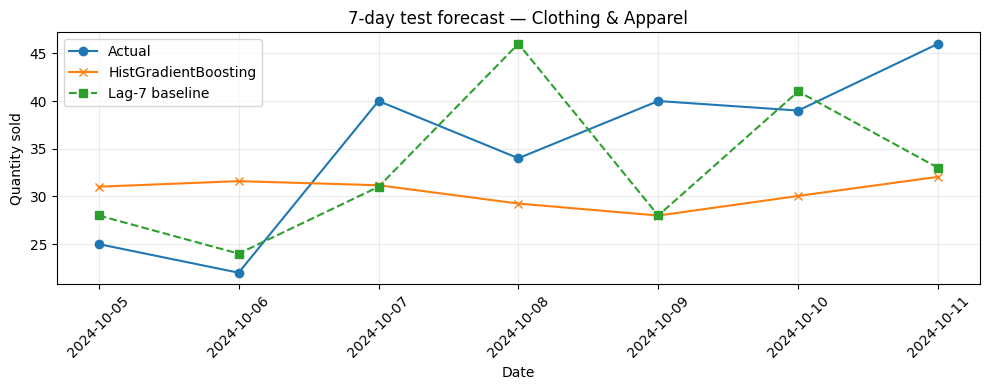

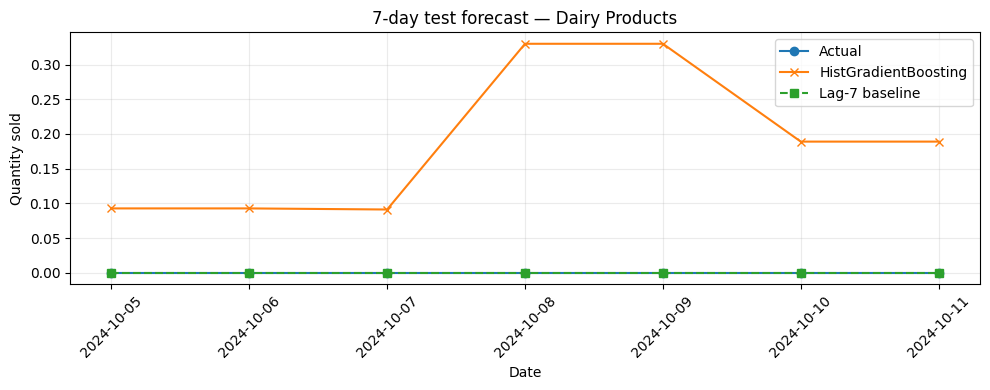

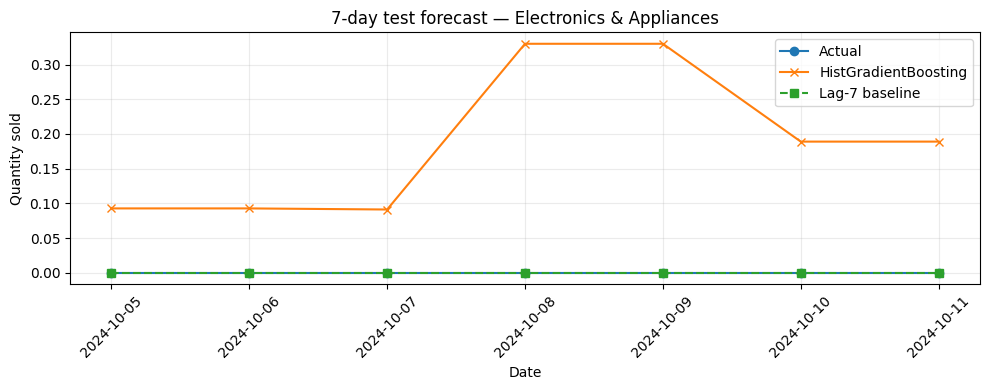

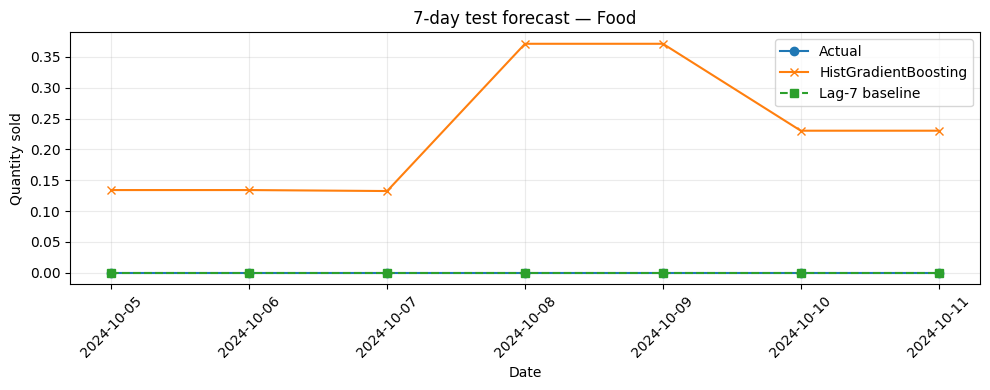

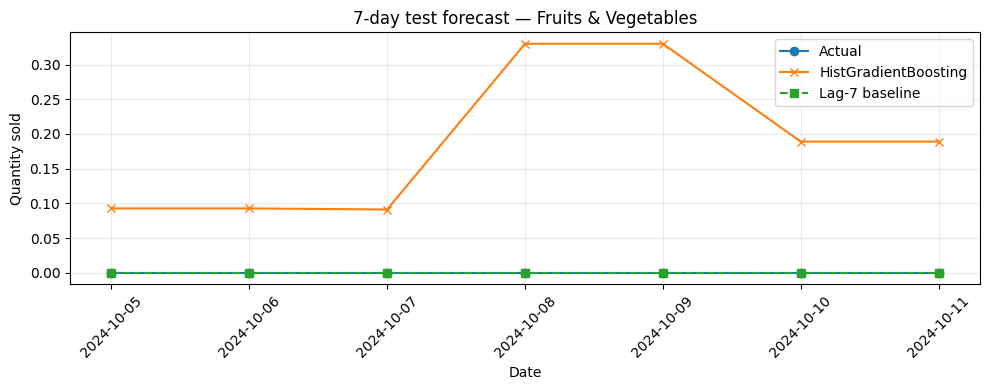

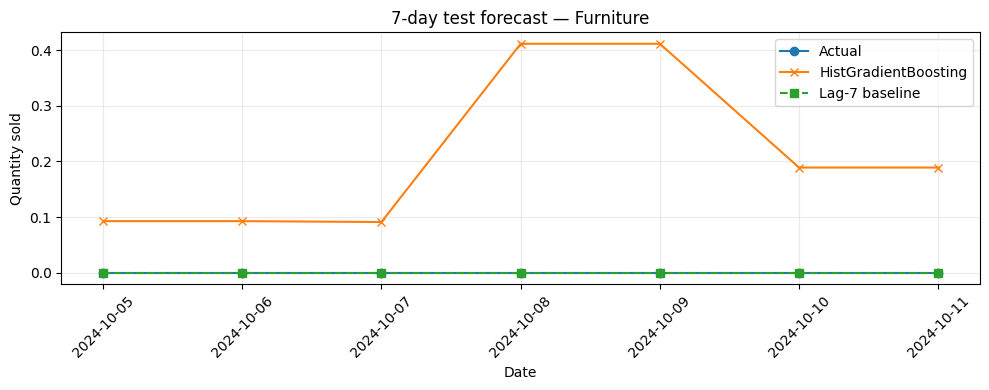

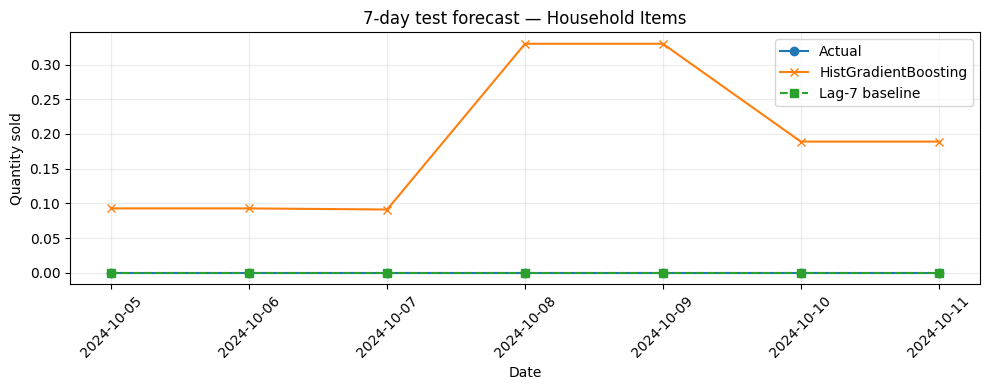

In [22]:
for category in categories:
    part = test_results[test_results[GROUP_COL] == category].sort_values("date")

    plt.figure(figsize=(10, 4))
    plt.plot(part["date"], part["actual"], marker="o", label="Actual")
    plt.plot(part["date"], part["hgb_prediction"], marker="x", label="HistGradientBoosting")
    plt.plot(part["date"], part["baseline_prediction"], marker="s", linestyle="--", label="Lag-7 baseline")

    plt.title(f"7-day test forecast — {category}")
    plt.xlabel("Date")
    plt.ylabel("Quantity sold")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Section 23 — Train the production model on all available historical rows

This production model is trained on all feature rows. The forecast dates are generated separately after each category's own last observed date.

Because the categories have different last dates in this source file, these forecasts will not share one common calendar week.

In [23]:
production_model = HistGradientBoostingRegressor(
    **best_params,
    early_stopping=False,
    random_state=RANDOM_STATE
)

production_model.fit(
    feature_data[feature_columns],
    feature_data[TARGET]
)

future_dates_by_category = {}

for category in categories:
    last_observed_date = panel.loc[
        panel[GROUP_COL] == category, "date"
    ].max()

    future_dates_by_category[category] = pd.date_range(
        start=last_observed_date + pd.Timedelta(days=1),
        periods=HORIZON,
        freq="D"
    )

forecast_date_union = sorted({
    date
    for dates in future_dates_by_category.values()
    for date in dates
})

print("Category-specific forecast starts:")
for category in categories:
    print(
        category,
        future_dates_by_category[category][0].date(),
        "to",
        future_dates_by_category[category][-1].date()
    )

today = pd.Timestamp.today().normalize()
print("\nData freshness relative to today's date:")
for category in categories:
    last_date = panel.loc[panel[GROUP_COL] == category, "date"].max()
    age_days = (today - last_date).days
    print(category, "last data:", last_date.date(), "| age:", age_days, "days")

print(
    "\nIf these dates are old, this is a historical demonstration forecast, "
    "not a current demand forecast."
)

Category-specific forecast starts:
Clothing & Apparel 2024-10-12 to 2024-10-18
Dairy Products 2024-10-12 to 2024-10-18
Electronics & Appliances 2024-10-12 to 2024-10-18
Food 2024-10-12 to 2024-10-18
Fruits & Vegetables 2024-10-12 to 2024-10-18
Furniture 2024-10-12 to 2024-10-18
Household Items 2024-10-12 to 2024-10-18

Data freshness relative to today's date:
Clothing & Apparel last data: 2024-10-11 | age: 751 days
Dairy Products last data: 2024-10-11 | age: 751 days
Electronics & Appliances last data: 2024-10-11 | age: 751 days
Food last data: 2024-10-11 | age: 751 days
Fruits & Vegetables last data: 2024-10-11 | age: 751 days
Furniture last data: 2024-10-11 | age: 751 days
Household Items last data: 2024-10-11 | age: 751 days

If these dates are old, this is a historical demonstration forecast, not a current demand forecast.


## Section 24 — Create a future festival-calendar template

The model uses festival features, so future predictions require real festival inputs.

This section creates a template for every date needed by the category-specific forecast. Known dates are prefilled from the source calendar. Dates outside the source history remain blank and must be completed using a verified festival calendar.

Do not leave blanks and do not replace them with arbitrary placeholder values.

In [24]:
future_calendar_template = pd.DataFrame({
    "saleDate": pd.to_datetime(forecast_date_union)
})

known_calendar = calendar_daily.rename(columns={"date": "saleDate"})

future_calendar_template = future_calendar_template.merge(
    known_calendar,
    on="saleDate",
    how="left"
)

template_path = OUTPUT_DIR / "future_calendar_template.csv"
future_calendar_template.to_csv(template_path, index=False)

print("Future calendar template saved to:", template_path.resolve())
display(future_calendar_template)

FUTURE_CALENDAR_PATH = OUTPUT_DIR / "future_calendar_completed.csv"
print(
    "\nEdit the template, fill all missing festival values, and save the completed file as:",
    FUTURE_CALENDAR_PATH
)

Future calendar template saved to: /content/supplysense_corrected_outputs/future_calendar_template.csv


,saleDate,Festival_Nearby_Within_10_Days,Days_To_Festival
0,2024-10-12,NaN,NaN
1,2024-10-13,NaN,NaN
2,2024-10-14,NaN,NaN
3,2024-10-15,NaN,NaN
4,2024-10-16,NaN,NaN
5,2024-10-17,NaN,NaN
6,2024-10-18,NaN,NaN



Edit the template, fill all missing festival values, and save the completed file as: supplysense_corrected_outputs/future_calendar_completed.csv


## Section 25 — Generate the category-specific 7-day forecast (after completing the calendar)

In [25]:
future_forecast = None

if FUTURE_CALENDAR_PATH.exists():
    future_calendar = pd.read_csv(FUTURE_CALENDAR_PATH)
    future_calendar["saleDate"] = pd.to_datetime(
        future_calendar["saleDate"], errors="coerce"
    )

    required_future_columns = ["saleDate"] + FESTIVAL_FEATURES
    missing_future_columns = sorted(
        set(required_future_columns) - set(future_calendar.columns)
    )

    if missing_future_columns:
        raise ValueError(
            f"Completed future calendar is missing columns: {missing_future_columns}"
        )

    if future_calendar["saleDate"].duplicated().any():
        raise ValueError("Future calendar contains duplicate dates.")

    future_calendar = future_calendar.set_index("saleDate")

    missing_dates = [
        d for d in forecast_date_union
        if d not in future_calendar.index
    ]

    if missing_dates:
        raise ValueError(f"Future calendar missing dates: {missing_dates}")

    future_values = future_calendar.loc[forecast_date_union, FESTIVAL_FEATURES]

    if future_values.isna().any().any():
        missing_rows = future_values[future_values.isna().any(axis=1)]
        raise ValueError(
            "Complete the festival values for these dates before forecasting:\n"
            + str(missing_rows)
        )

    if not future_values[FESTIVAL_FLAG].isin([0, 1]).all():
        raise ValueError("Future festival flag must be 0 or 1.")

    if (future_values[DAYS_TO_FESTIVAL] < 0).any():
        raise ValueError("Future Days_To_Festival cannot be negative.")

    future_calendar_lookup = {
        pd.Timestamp(date): row.to_dict()
        for date, row in future_values.iterrows()
    }

    combined_calendar_lookup = {
        **calendar_by_date,
        **future_calendar_lookup
    }

    future_forecast = recursive_forecast(
        model=best_model,
        history_data=panel,
        dates_by_category=future_dates_by_category,
        calendar_lookup=combined_calendar_lookup,
        use_model=(best_model_name == "HistGradientBoosting")
    )

    future_forecast = future_forecast.rename(
        columns={
            "date": "Date",
            GROUP_COL: "Product_Category",
            "prediction": "Predicted_Quantity"
        }
    )

    print("Category-specific 7-day forecast:")
    display(future_forecast.round(2))

else:
    print("Forecast not generated yet.")
    print("Complete the future calendar template and save it as:")
    print(FUTURE_CALENDAR_PATH)

Forecast not generated yet.
Complete the future calendar template and save it as:
supplysense_corrected_outputs/future_calendar_completed.csv


## Section 26 — Save the selected best model, metrics, predictions and summary

The winner is selected from rolling validation WAPE (MAE tie-breaker). The untouched test set is retained for final reporting only. The artifact records whether the winner is HistGradientBoosting or the recursive Lag-7 baseline.


In [26]:
# Select the winner using rolling validation results (not the test set).
# WAPE is the primary metric; MAE is the tie-breaker.
validation_ranked = validation_comparison.sort_values(
    ["WAPE (%)", "MAE"], ascending=[True, True]
).reset_index(drop=True)
best_model_name = validation_ranked.loc[0, "Model"]

if best_model_name == "HistGradientBoosting":
    best_model = production_model  # retrained on all available pre-deployment data
    best_model_params = best_params
else:
    best_model = None  # Lag-7 is a deterministic recursive baseline, not a fitted estimator.
    best_model_params = None

model_artifact = {
    "model_name": best_model_name,
    "model_type": "sklearn_estimator" if best_model_name == "HistGradientBoosting" else "recursive_lag_7",
    "model": best_model,
    "selection_metric": "validation WAPE (%)",
    "validation_comparison": validation_comparison.to_dict(orient="records"),
    "feature_columns": feature_columns,
    "categories": categories,
    "target": TARGET,
    "group_column": GROUP_COL,
    "horizon_days": HORIZON,
    "best_params": best_model_params,
    "lags": list(LAGS),
    "rolling_windows": list(ROLLING_WINDOWS),
    "festival_features": FESTIVAL_FEATURES,
    "category_last_observed_dates": {
        category: str(panel.loc[panel[GROUP_COL] == category, "date"].max().date())
        for category in categories
    }
}

model_path = OUTPUT_DIR / "supplysense_best_model.joblib"
joblib.dump(model_artifact, model_path)

comparison.to_csv(OUTPUT_DIR / "test_metrics_comparison.csv", index=False)
category_comparison.to_csv(OUTPUT_DIR / "category_metrics.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
tuning_table.to_csv(OUTPUT_DIR / "validation_tuning_results.csv", index=False)
future_calendar_template.to_csv(OUTPUT_DIR / "future_calendar_template.csv", index=False)

if future_forecast is not None:
    future_forecast.to_csv(
        OUTPUT_DIR / "category_specific_7_day_forecast.csv",
        index=False
    )

def to_json_safe(value):
    if isinstance(value, dict):
        return {str(k): to_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    return value

summary = {
    "project": "SupplySense Demand Forecasting",
    "selected_model": best_model_name,
    "selection_metric": "validation WAPE (%) with MAE tie-breaker",
    "forecast_horizon_days": HORIZON,
    "common_evaluation_start": str(common_start.date()),
    "common_evaluation_end": str(common_end.date()),
    "test_start": str(test_dates_common[0].date()),
    "test_end": str(test_dates_common[-1].date()),
    "selected_parameters": best_model_params,
    "histgradientboosting_test_metrics": hgb_metrics,
    "lag7_baseline_test_metrics": baseline_metrics,
    "category_coverage": {
        category: {
            "start": str(coverage.loc[category, "first_date"].date()),
            "end": str(coverage.loc[category, "last_date"].date())
        }
        for category in categories
    },
    "future_forecast_generated": future_forecast is not None
}

with open(OUTPUT_DIR / "summary.json", "w") as f:
    json.dump(to_json_safe(summary), f, indent=4)

print("Selected best model:", best_model_name)
print("Saved model:", model_path.resolve())
print("All outputs saved in:", OUTPUT_DIR.resolve())


Selected best model: Lag-7 Baseline
Saved model: /content/supplysense_corrected_outputs/supplysense_best_model.joblib
All outputs saved in: /content/supplysense_corrected_outputs


## Section 27 — Final report

In [27]:
print("=" * 72)
print("SUPPLYSENSE — CORRECTED DEMAND FORECASTING RESULTS")
print("=" * 72)
print("\nSelected production model (validation WAPE, MAE tie-break):", best_model_name)
print("Forecast horizon:", HORIZON, "days")
print("Common test period:", test_dates_common[0].date(), "to", test_dates_common[-1].date())
print("\nValidation comparison:")
display(validation_comparison.round(4))
print("\nUntouched test comparison (reporting only):")
display(comparison.round(4))
print("\nSelected hyperparameters:", best_model_params)
print("\nOutput directory:", OUTPUT_DIR.resolve())
print("Saved artifact:", OUTPUT_DIR / "supplysense_best_model.joblib")
print("=" * 72)


SUPPLYSENSE — CORRECTED DEMAND FORECASTING RESULTS

Selected production model (validation WAPE, MAE tie-break): Lag-7 Baseline
Forecast horizon: 7 days
Common test period: 2024-10-05 to 2024-10-11

Validation comparison:


,Model,MAE,RMSE,R2,WAPE (%),Bias (%)
0,HistGradientBoosting,7.3180,17.5841,-1.6174,174.5786,156.2195
1,Lag-7 Baseline,1.8082,5.9085,0.7045,43.1353,1.6553



Untouched test comparison (reporting only):


,Model,MAE,RMSE,R2,WAPE (%),Bias (%),MASE (macro)
0,HistGradientBoosting,1.4784,3.6416,0.9174,29.4476,-9.9699,0.4344
1,Lag-7 Baseline,1.0816,3.3655,0.9295,21.5447,-6.0976,0.3515



Selected hyperparameters: None

Output directory: /content/supplysense_corrected_outputs
Saved artifact: supplysense_corrected_outputs/supplysense_best_model.joblib


## Section 28 — Load the saved model for later inference

This demonstrates loading the saved artifact. For a new forecast, you must also supply recent complete sales history and a verified future festival calendar, then construct features with the same definitions used above.

In [28]:
loaded_artifact = joblib.load(OUTPUT_DIR / "supplysense_best_model.joblib")

print("Loaded best model successfully.")
print("Selected model:", loaded_artifact["model_name"])
print("Model type:", loaded_artifact["model_type"])
print("Forecast horizon:", loaded_artifact["horizon_days"])
if loaded_artifact["model_type"] == "sklearn_estimator":
    loaded_model = loaded_artifact["model"]
    loaded_features = loaded_artifact["feature_columns"]
    print("Expected feature count:", len(loaded_features))
else:
    print("Lag-7 baseline selected: use recursive 7-day lag forecasting; no fitted estimator is required.")


Loaded best model successfully.
Selected model: Lag-7 Baseline
Model type: recursive_lag_7
Forecast horizon: 7
Lag-7 baseline selected: use recursive 7-day lag forecasting; no fitted estimator is required.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [29]:
import shutil
from google.colab import files
import os

folder_path = "/content/supplysense_corrected_outputs"
zip_path = "/content/supplysense_corrected_outputs.zip"

# Verify folder exists
if not os.path.exists(folder_path):
    raise FileNotFoundError(f"Folder not found: {folder_path}")

# Compress the entire folder
shutil.make_archive(
    "/content/supplysense_corrected_outputs",
    "zip",
    root_dir="/content",
    base_dir="supplysense_corrected_outputs"
)

# Download ZIP
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>